# LT01 — Historical customer value (RFM, tiers, Pareto)

Question: what did each customer contribute in the past, and how well does that history rank the value they produce next?

Data: Online Retail II (UCI), Kaggle slug `mashlyn/online-retail-ii-uci`, read in place.
Observation window: first 12 months. Holdout window: the next 12 months. Cancellations and returns are removed.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from historical_clv.data import load_online_retail, make_windows, split_windows
from historical_clv.metrics import holdout_revenue, mae, rmse, top_decile_capture
from historical_clv.plots import plot_pareto_curve, plot_tier_summary, plot_value_distribution
from historical_clv.rfm import TIER_LABELS, assign_value_tiers, build_rfm, pareto_share

DATA_PATH = Path(os.environ.get("CLV_DATA_PATH", "/kaggle/input/online-retail-ii-uci/online_retail_II.csv"))
FIG = Path("../reports/figures")
REPORTS = Path("../reports")
FIG.mkdir(parents=True, exist_ok=True)
REPORTS.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 1. Load, clean, cut

In [2]:
tx = load_online_retail(DATA_PATH)
print(f"clean rows: {len(tx):,} | customers: {tx['customer_id'].nunique():,} | dates {tx['day'].min().date()} to {tx['day'].max().date()}")

clean rows: 805,549 | customers: 5,878 | dates 2009-12-01 to 2011-12-09


In [3]:
windows = make_windows(tx["day"].min(), t_obs_months=12, t_hold_months=12)
obs, hold = split_windows(tx, windows)
title_ctx = f"Online Retail II | obs {windows.obs_start.date()} to {windows.obs_end.date()} | hold to {windows.hold_end.date()} | LT01 historical"
print(f"observation rows: {len(obs):,} | holdout rows: {len(hold):,}")
print(f"obs customers: {obs['customer_id'].nunique():,} | holdout customers: {hold['customer_id'].nunique():,}")

observation rows: 393,160 | holdout rows: 395,084
obs customers: 4,266 | holdout customers: 4,297


## 2. RFM summary and value tiers (observation window only)

In [4]:
rfm = build_rfm(obs, windows.obs_end)
rfm["tier"] = assign_value_tiers(rfm)
rfm["holdout_revenue"] = holdout_revenue(hold, rfm.index)
rfm["holdout_buyer"] = rfm["holdout_revenue"] > 0
rfm.head()

,purchase_days,first_day,last_day,historical_revenue,frequency,recency_days,T_days,monetary_avg,tier,holdout_revenue,holdout_buyer
customer_id,,,,,,,,,,,
12346,7,2009-12-14,2010-06-28,372.86,6,156,352,53.265714,Q2,77183.60,True
12347,1,2010-10-31,2010-10-31,611.53,0,31,31,611.530000,Q3,4796.97,True
12348,1,2010-09-27,2010-09-27,222.16,0,65,65,222.160000,Q1 lowest,1797.24,True
12349,3,2010-04-29,2010-10-28,2671.14,2,34,216,890.380000,Q5 highest,1757.55,True
12351,1,2010-11-29,2010-11-29,300.93,0,2,2,300.930000,Q2,0.00,False


In [5]:
total_obs_revenue = rfm["historical_revenue"].sum()
tier_table = (
    rfm.groupby("tier")
    .agg(
        customers=("historical_revenue", "size"),
        revenue=("historical_revenue", "sum"),
        mean_historical_revenue=("historical_revenue", "mean"),
        repeat_rate=("frequency", lambda s: float((s > 0).mean())),
        holdout_buyer_rate=("holdout_buyer", "mean"),
    )
    .reindex(TIER_LABELS)
)
tier_table["revenue_share"] = tier_table["revenue"] / total_obs_revenue
tier_table.reset_index(names="tier")

,tier,customers,revenue,mean_historical_revenue,repeat_rate,holdout_buyer_rate,revenue_share
0,Q1 lowest,854,129716.440,151.892787,0.118267,0.336066,0.015225
1,Q2,853,309082.171,362.347211,0.406800,0.493552,0.036277
2,Q3,853,604522.842,708.702042,0.804220,0.671747,0.070952
3,Q4,853,1236345.820,1449.408933,0.929660,0.773740,0.145109
4,Q5 highest,853,6240458.001,7315.894491,0.974209,0.905041,0.732437


## 3. Pareto share

In [6]:
pareto_top20 = pareto_share(rfm["historical_revenue"], top_fraction=0.2)
pareto_top10 = pareto_share(rfm["historical_revenue"], top_fraction=0.1)
print(f"top 20% of customers hold {pareto_top20:.1%} of observation revenue")
print(f"top 10% of customers hold {pareto_top10:.1%} of observation revenue")

top 20% of customers hold 73.3% of observation revenue
top 10% of customers hold 59.6% of observation revenue


## 4. Does history predict the holdout? Baselines compared

Predictions use observation-window data only. Mean-value baseline: a constant equal to the mean historical revenue of the cohort.
Historical model: the customer's own observation-window revenue.

In [7]:
y = rfm["holdout_revenue"].to_numpy()
pred_hist = rfm["historical_revenue"].to_numpy()
pred_mean = np.full_like(y, rfm["historical_revenue"].mean(), dtype=float)

metrics = pd.DataFrame(
    {
        "model": ["mean-value baseline", "historical revenue (LT01)"],
        "MAE": [mae(y, pred_mean), mae(y, pred_hist)],
        "RMSE": [rmse(y, pred_mean), rmse(y, pred_hist)],
        "top10_capture": [top_decile_capture(y, pred_mean), top_decile_capture(y, pred_hist)],
    }
)
metrics

,model,MAE,RMSE,top10_capture
0,mean-value baseline,2336.157460,8618.825252,0.141654
1,historical revenue (LT01),1165.804963,4334.734335,0.598440


Calibration of expected purchases does not apply here, since LT01 has no purchase model. It is reported in LT02.

In [8]:
fig_title = f"Historical revenue vs holdout | {title_ctx}"
plot_value_distribution(rfm, f"Observation revenue per customer | {title_ctx}", FIG / "lt01_value_distribution.png")
plot_pareto_curve(rfm["historical_revenue"].to_numpy(), f"Pareto curve | {title_ctx}", FIG / "lt01_pareto_curve.png")
tier_plot = tier_table.reset_index(names="tier")
plot_tier_summary(tier_plot, f"Revenue share by value tier | {title_ctx}", FIG / "lt01_tier_revenue_share.png")

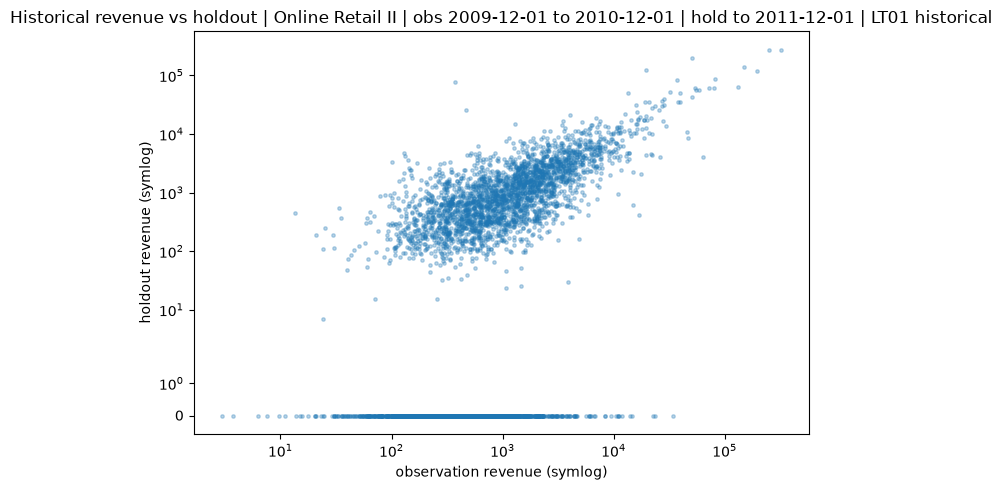

In [9]:
plt.figure(figsize=(7, 5))
plt.scatter(rfm["historical_revenue"], rfm["holdout_revenue"], s=6, alpha=0.3)
plt.xscale("symlog")
plt.yscale("symlog")
plt.xlabel("observation revenue (symlog)")
plt.ylabel("holdout revenue (symlog)")
plt.title(fig_title)
plt.tight_layout()
plt.savefig(FIG / "lt01_history_vs_holdout.png", dpi=150)
plt.show()

## 5. Save tables

In [10]:
tier_table.to_csv(REPORTS / "lt01_tier_table.csv")
metrics.to_csv(REPORTS / "lt01_metrics.csv", index=False)
summary = {
    "dataset": "mashlyn/online-retail-ii-uci",
    "obs_window": [str(windows.obs_start.date()), str(windows.obs_end.date())],
    "holdout_window": [str(windows.obs_end.date()), str(windows.hold_end.date())],
    "customers_observed": int(len(rfm)),
    "holdout_buyer_rate": float(rfm["holdout_buyer"].mean()),
    "pareto_top20_revenue_share": pareto_top20,
    "pareto_top10_revenue_share": pareto_top10,
}
(REPORTS / "lt01_summary.json").write_text(json.dumps(summary, indent=2))
summary

{'dataset': 'mashlyn/online-retail-ii-uci',
 'obs_window': ['2009-12-01', '2010-12-01'],
 'holdout_window': ['2010-12-01', '2011-12-01'],
 'customers_observed': 4266,
 'holdout_buyer_rate': 0.6359587435536803,
 'pareto_top20_revenue_share': 0.732683241178362,
 'pareto_top10_revenue_share': 0.5964081926713699}